# SaafHawa inference decision
AI4015 Assignment Beta Q1 · FAST-NUCES Karachi · Fall 2026 · 23K-0073

Run from the submission directory. The Python and workbook models use the same prescribed traffic assumptions. Provider prices are dated quotes, and the timing experiment is qualified only when the included CSV passes the two-day check.

In [1]:
from calculations import *
print(dict(R=R,D=D,Q=Q,N=N,p=P,H=H,B=B,T=T))
print('Call | prompt | visible completion | expected attempts')
for row in CALLS: print(*row, sep=' | ')
print(f'Expected retries = {(N-1)*P:.2f}')
print(f'Expected input, output, requests per query = {EI:,}, {EO:,}, {ER}')
print(f'Month: {MQ:,} queries, {MI:,.0f} input, {MO:,.0f} output, {MR:,.0f} requests')
print('Peak QPM, RPM, input TPM, output TPM, combined TPM:', [round(x,2) for x in PEAK])

{'R': 73, 'D': 5, 'Q': 3325, 'N': 6, 'p': 0.09, 'H': 5, 'B': 1930, 'T': 9}
Call | prompt | visible completion | expected attempts
1 | 2000 | 350 | 1.09
2 | 2800 | 350 | 1.09
3 | 3600 | 350 | 1.09
4 | 4400 | 350 | 1.09
5 | 5200 | 350 | 1.09
6 | 6000 | 600 | 1
Expected retries = 0.45
Expected input, output, requests per query = 25,620.0, 2,507.5, 6.45
Month: 166,250 queries, 4,259,325,000 input, 416,871,875 output, 1,072,312 requests
Peak QPM, RPM, input TPM, output TPM, combined TPM: [48.49, 312.76, 1242303.12, 121587.63, 1363890.76]


## Token and pricing equations
For the first five calls, $w_k=1+p$. For the last, $w_N=1$. Sum $w_k I(k)$ and $w_k O(k)$. Monthly queries are $Q[(30-H)+5H]$. Peak QPM is $5Q(0.35)/120$.
    
Cost in USD is $(I_m a+O_m b)/10^6$. For the verified eligible prefix of $C$ tokens, add $R_m C[h(c-a)+(1-h)(w-a)]/10^6$ using hit fraction $h$, read rate $c$, and full write rate $w$. The cold and warm scenarios are modeled cases.

gpt-6-luna                                      634.37    672.11    585.30    515.85   +100:    53.62  Budget: True/True
gpt-6.1-terra                                  6343.68   6721.14   5815.25   5090.54   +100:   536.16  Budget: False/False
claude-haiku-5-5                                634.37    674.58    582.09    508.10   +100:    53.62  Budget: True/True
gemini-3.1-flash-lite                          1690.14   1690.14   1690.14   1690.14   +100:   160.85  Budget: True/True
gemini-3.5-flash-lite                          2319.98   2319.98   2319.98   2319.98   +100:   268.08  Budget: False/False
grok-4.7                                      11019.88  11019.88  11019.88  11019.88   +100:   643.39  Budget: False/False
meta-llama/llama-3.1-8b-instruct                101.86    101.86    101.86    101.86   +100:     4.29  Budget: True/True
qwen/qwen3-14b                                  488.93    488.93    488.93    488.93   +100:    20.59  Budget: True/True
google/gemma-3-27b-it     

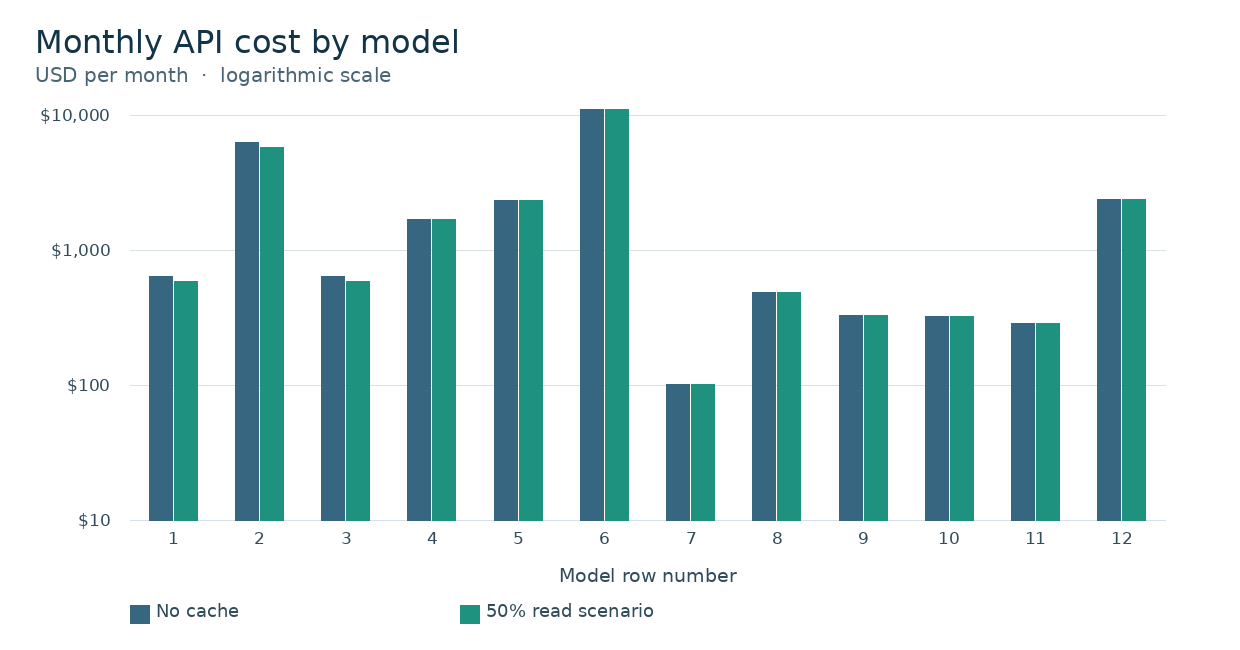

In [2]:
from plots import plots
plots()
for m in MODELS:
    base=monthly_cost(m)
    cold=monthly_cost(m,0,caching=True)
    moderate=monthly_cost(m,.5,caching=True)
    warm=monthly_cost(m,.9,caching=True)
    extra=monthly_cost(m,reasoning=100)-base
    print(f'{m["model"]:44} {base:9.2f} {cold:9.2f} {moderate:9.2f} {warm:9.2f}   +100: {extra:8.2f}  Budget: {base<=B}/{moderate<=B}')
from IPython.display import Image, display
display(Image(filename="api_cost.png"))

## GPU memory and step cost
$mathrm{KV}=2(40)(8)(128)(6600)(2)$ bytes. Weight bytes are parameter count multiplied by bytes per weight. Assuming 30 seconds mean service time, concurrent sessions are $lambda s$ and GPU replicas are the ceiling of sessions divided by memory capacity. The no-crossover proof compares the API slope with the lower linear envelope of the GPU steps.

GPU config: {'num_hidden_layers': 40, 'num_key_value_heads': 8, 'head_dim': 128, 'hidden_size': 5120, 'num_attention_heads': 40, 'max_position_embeddings': 40960}
16 bits: 27.567 GiB
8 bits: 13.784 GiB
4 bits: 6.892 GiB
KV = 1,081,344,000 bytes, availability after reserve and weights = 14.708 GiB
14 sessions/GPU, 2 GPUs, secure monthly USD 1281.60
API slope 0.03625, GPU width 1920, Q* = None


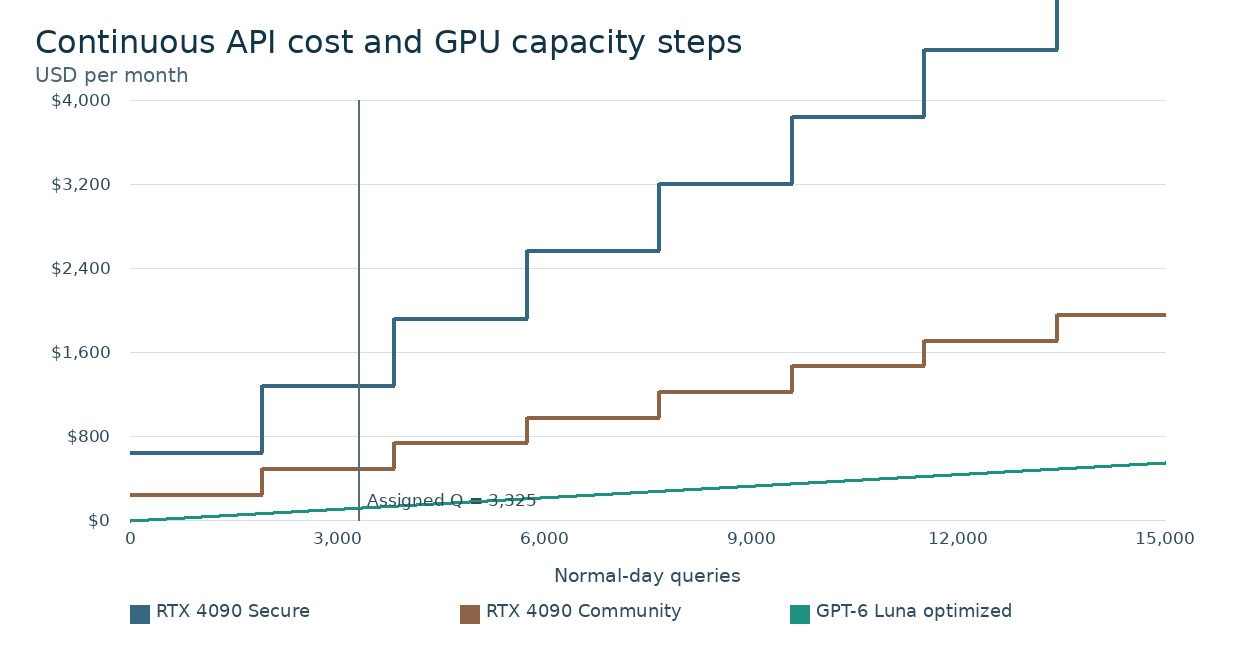

In [3]:
print('GPU config:', {k:CONFIG[k] for k in ['num_hidden_layers','num_key_value_heads','head_dim','hidden_size','num_attention_heads','max_position_embeddings']})
for bits in (16,8,4): print(f'{bits} bits: {PARAMETERS*bits/8/2**30:.3f} GiB')
print(f'KV = {KV:,} bytes, availability after reserve and weights = {FREE/2**30:.3f} GiB')
print(f'{CAP} sessions/GPU, {GPU_COUNT} GPUs, secure monthly USD {gpu_cost(Q):.2f}')
print(f'API slope {SLOPE:.5f}, GPU width {BREAK_CAP:.0f}, Q* = {crossover()}')
from IPython.display import Image, display
display(Image(filename="break_even.png"))

## Timings and latency
When the two-day timing log qualifies, the prescribed sequential calculation uses the successful pooled median. The API-only median is a separate diagnostic. Each call starts with TTFT at a 2,000-token reference plus $(I_k-2000)/4000$ seconds of illustrative extra prefill. Decoding adds $(O_k-1)/v$ because TTFT already includes the first token. The optimized path has a single LLM call after a parallel tool stage. Its stage proxy is the larger of the two remote medians plus both local medians.

In [4]:
summary, qualified, pooled, api = tool_results()
for row in summary: print(row)
print(f'Qualified={qualified}; successful pooled median={pooled:.9f}s; API-only median={api:.6f}s')
for m in MODELS[:2]:
    print(m["model"], 'baseline full/first, optimized full/first',
          [round(x,3) for x in latency(m["ttft"], m["tps"], pooled if qualified else api, optimized_tool_seconds=critical_path_proxy(summary))])
print('The tool stage and full path require verification under real load.')

('OpenAQ', 50, 35, 0, 2, 0.7433030999964103)
('Open-Meteo', 70, 70, 70, 2, 0.18632245000480907)
('heat_index', 70, 70, 70, 2, 8.75000114319846e-06)
('advisory_lookup', 70, 70, 70, 2, 1.2999953469261527e-06)
Qualified=True; successful pooled median=0.000009400s; API-only median=0.244081s
gpt-6-luna baseline full/first, optimized full/first [42.192, 35.537, 6.25, 3.483]
gpt-6.1-terra baseline full/first, optimized full/first [55.848, 46.632, 7.774, 3.943]
The tool stage and full path require verification under real load.
